# MAE O3 · Online MLP at +8

**Completed online +8 comparison** · updated 2026-11-21T16:36:36+01:00.

Online MAE arrivals **72,000/72,000**. Delayed MLP updates **71,993**.


The online MLP starts from the same 88-input, 48/24-hidden-unit fit as the frozen +8 arm. Each forecast scores Skip, 0.25×, and 1× using the old O3 utility, −scaled MSE + 0.25 × scaled RankMe. Only the first action is executed. The forecast assumes seven subsequent 0.25× updates.

The worker stores the MAE state at forecast time. Once all eight arrivals have actually occurred, it reads the three matched branches from that state using the observed frames. It scores the issued forecast and then takes one online Adam update. Scalers stay fixed. Final origins with fewer than eight arrivals remaining use the original +1 Lasso.

The RMSE plots use the last 1,024 available targets for each point. Both nonzero actions are scored, with advantage measured relative to the matched Skip branch. Persistence predicts zero advantage. Frozen and online MLP forecasts are evaluated on the same origins and target draws.


## Realized MAE outcomes
| Policy | Stream MSE | Stream RankMe | O3 utility | Test MSE | Test RankMe |
| --- | ---: | ---: | ---: | ---: | ---: |
| Online MLP | 0.807271 | 3.15796 | -2.106923 | 0.928815 | 3.14766 |
| Frozen MLP | 0.801613 | 3.19699 | -2.036190 | 0.917865 | 3.30991 |

## Pooled +8 advantage RMSE
| Target | Online MLP | Frozen MLP | Persistence |
| --- | ---: | ---: | ---: |
| Current-image reconstruction MSE | 0.00388243 | 0.00925426 | 0.00464007 |
| Rolling-bank reconstruction MSE | 0.00150216 | 0.00251332 | 0.00145852 |
| RankMe | 0.0133445 | 0.016161 | 0.0138159 |
| Feature variance | 0.00206282 | 0.00255954 | 0.00219413 |

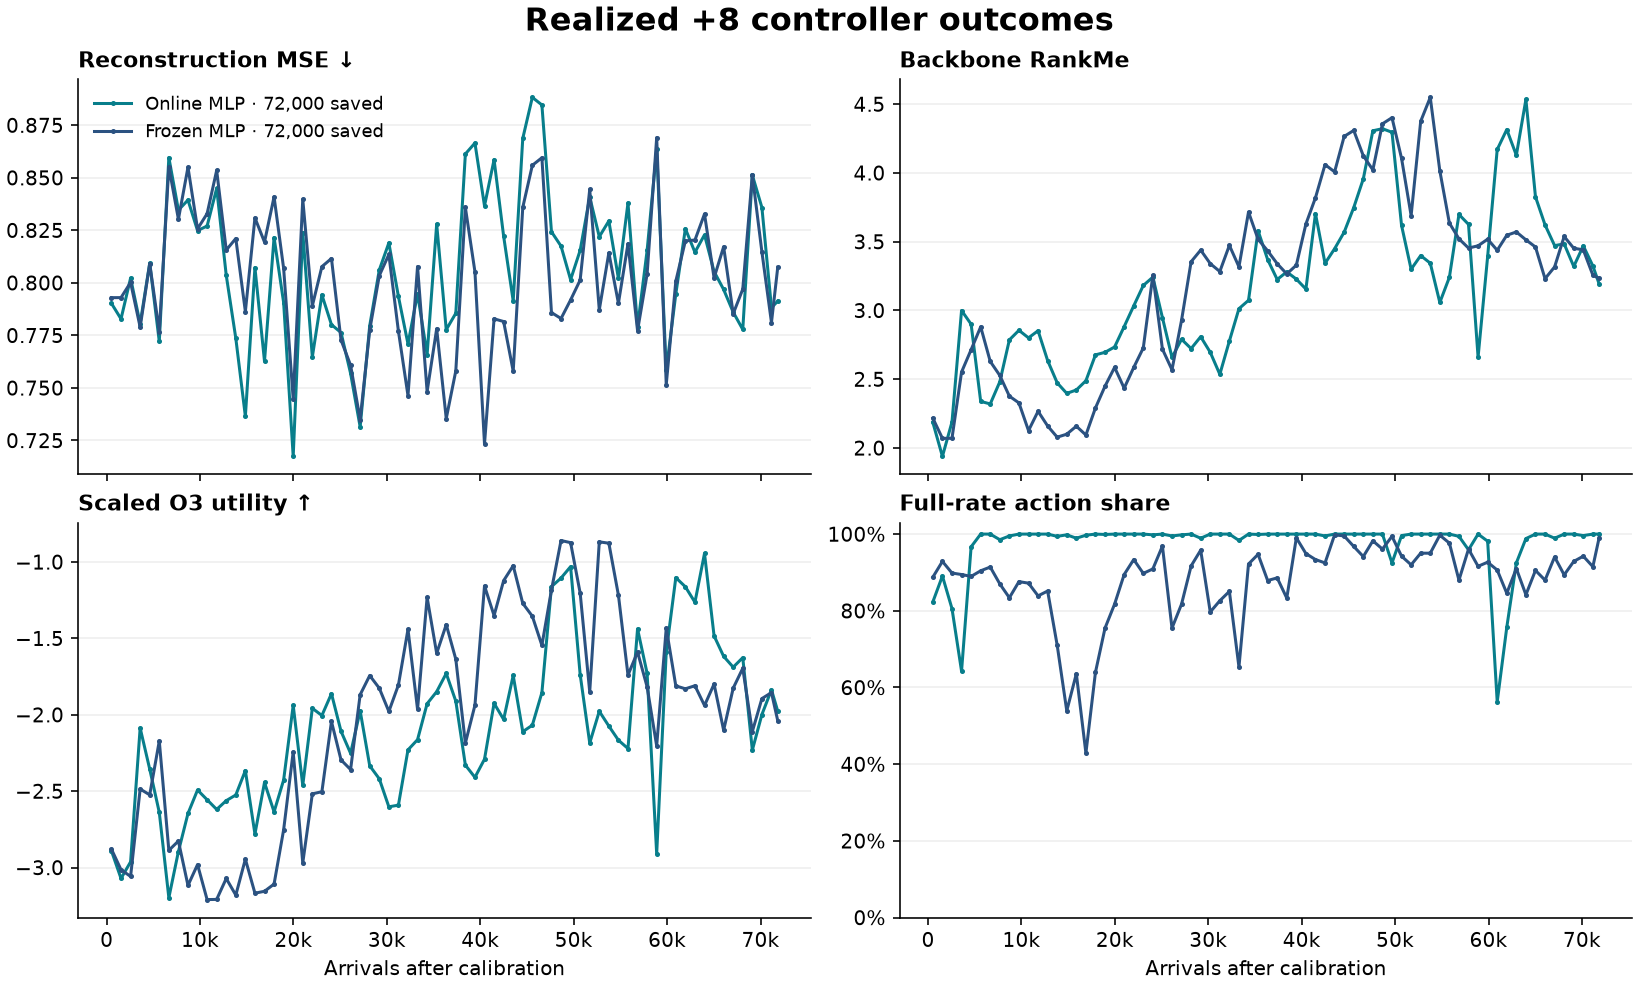

In [ ]:
from pathlib import Path
import sys
from IPython.display import display
import matplotlib.pyplot as plt

folder = Path('C:/CAFL-E/analysis/2026-11-09-one-step-mpc/o3-horizon8-online')
sys.path.insert(0,str(folder.parent.parent if folder.name == "smoke" else folder.parent))
from o3_online8_report import trajectories, read
figure = trajectories(folder, read(folder / "status.json"))
if figure is not None:
    display(figure)
    plt.close(figure)


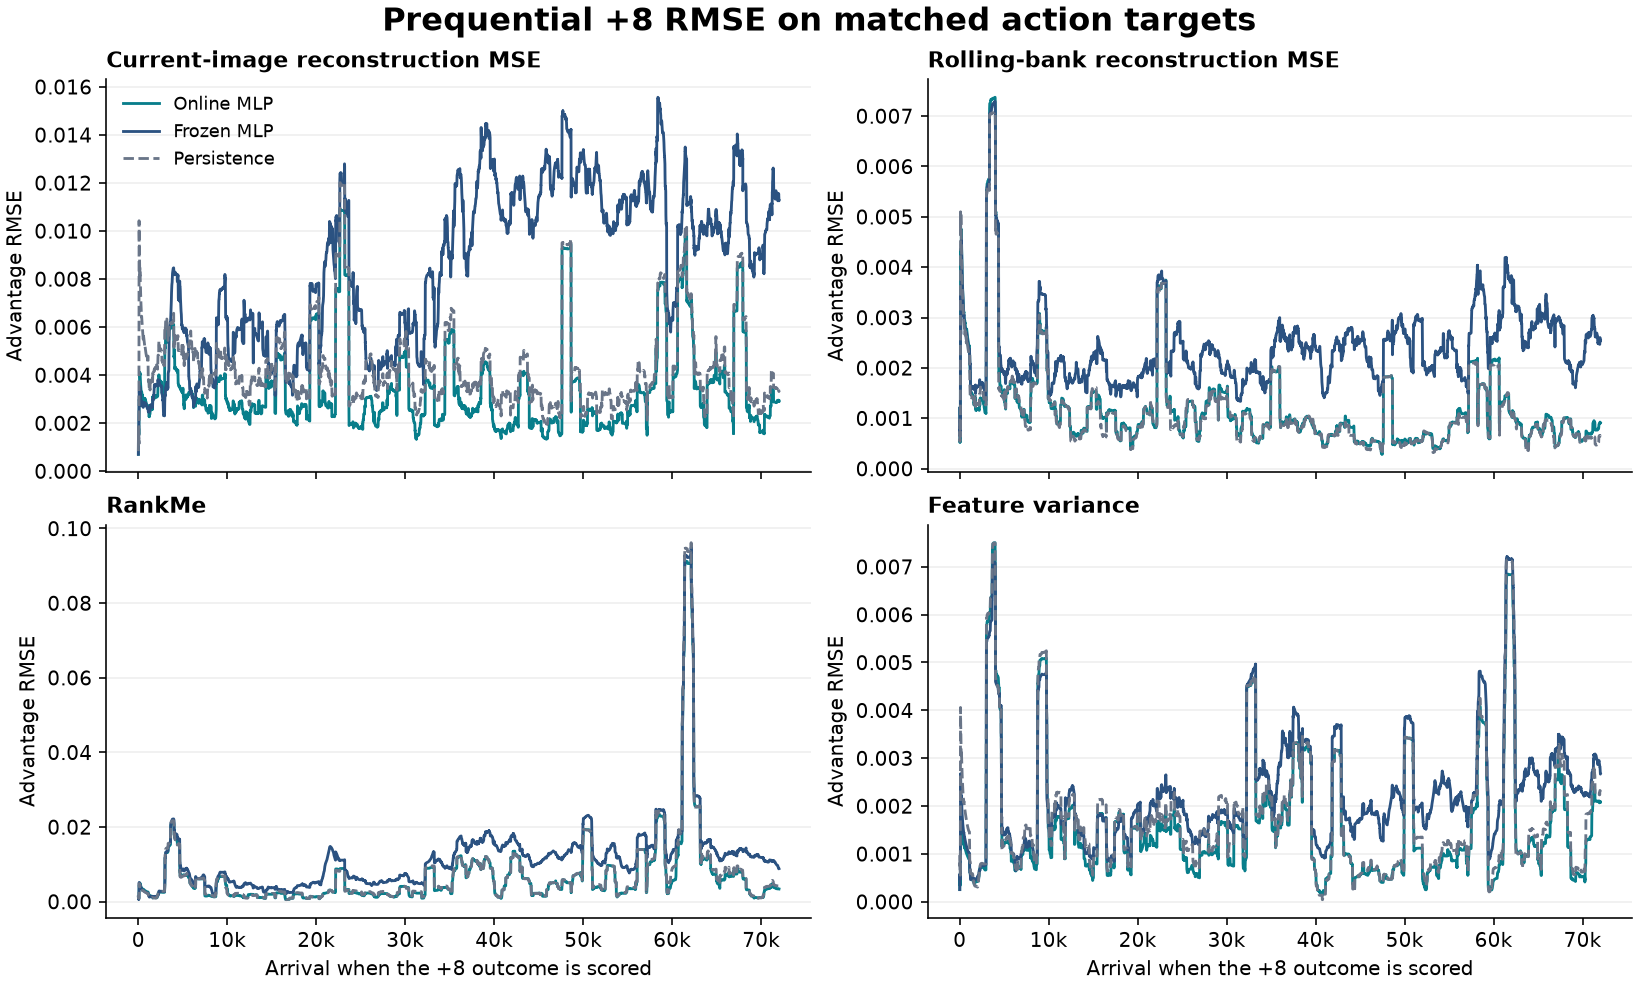

In [ ]:
from pathlib import Path
import sys
from IPython.display import display
import matplotlib.pyplot as plt

folder = Path('C:/CAFL-E/analysis/2026-11-09-one-step-mpc/o3-horizon8-online')
sys.path.insert(0,str(folder.parent.parent if folder.name == "smoke" else folder.parent))
from o3_online8_report import rmse, read
figure = rmse(folder, read(folder / "status.json"))
if figure is not None:
    display(figure)
    plt.close(figure)
